# Lab 07 — Grad-CAM on a Pretrained CNN

**Aim:** apply Grad-CAM to a pretrained CNN on one simple image and see how the heatmap changes when we change the **target class**, the **layer** and the **model**.

Grad-CAM answers: *which part of the image made the network pick this class?* It takes the feature maps of a conv layer, weights each map by how much the class score depends on it (the gradient), adds them up and keeps only the positive part.

Plan:
1. Load VGG-16 and check what it predicts for the image.
2. Implement Grad-CAM from scratch.
3. Show the heatmap and overlay for the predicted class.
4. Experiment 1 — a different class (dog vs cat).
5. Experiment 2 — a different model (AlexNet).

**Learning component** sections go one step further:
- check our code against the `pytorch-grad-cam` library, look at the top-5 classes and at different layers;
- implement **Grad-CAM++** and **Guided Grad-CAM** from scratch;
- *measure* how trustworthy each heatmap is with **deletion / insertion** curves;
- run a **sanity check** (randomise the model's weights and see if the heatmap breaks).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torchvision import models
from PIL import Image

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
plt.rcParams.update({"figure.dpi": 110})
print("torch", torch.__version__, "| device:", device)

torch 2.14.0+cu130 | device: cuda


## 1. Load the image
One simple image with **two** objects: a bulldog and a tabby cat. Two objects let us test whether Grad-CAM moves when we ask about a different class.

Size: (224, 224)


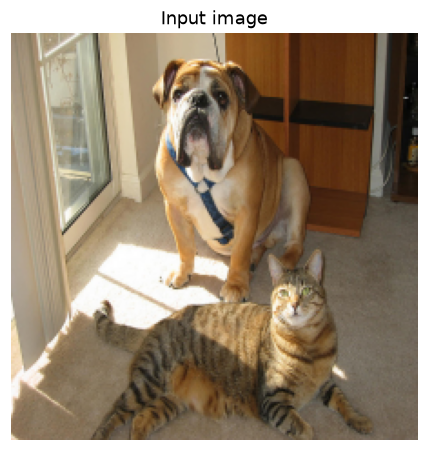

In [2]:
img = Image.open("data/both.png").convert("RGB")
print("Size:", img.size)
plt.imshow(img); plt.axis("off"); plt.title("Input image"); plt.show()

## 2. Pre-process
The pretrained models expect a 224×224 image normalised with the ImageNet mean and standard deviation. We also keep a plain 0–1 copy of the image for drawing overlays later.

In [3]:
weights_vgg = models.VGG16_Weights.IMAGENET1K_V1
preprocess = weights_vgg.transforms()          # resize 256 -> center-crop 224 -> tensor -> normalise
labels = weights_vgg.meta["categories"]       # 1000 ImageNet class names

x = preprocess(img).unsqueeze(0).to(device)   # shape (1, 3, 224, 224)

# undo the normalisation so we can show exactly what the model sees
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
rgb = (x[0].cpu() * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()
print("Input tensor:", tuple(x.shape))

Input tensor: (1, 3, 224, 224)


## 3. Load VGG-16 and check its prediction
`eval()` turns off dropout so the output is deterministic. We print the top-5 classes with their softmax probabilities.

In [4]:
vgg = models.vgg16(weights=weights_vgg).to(device).eval().requires_grad_(False)   # frozen: we never train

def top_k(model, x, k=5):
    with torch.no_grad():
        probs = F.softmax(model(x), dim=1)[0]
    p, idx = probs.topk(k)
    for rank, (pi, i) in enumerate(zip(p.tolist(), idx.tolist()), 1):
        print(f"{rank}. {labels[i]:<22} (class {i:>3})  p = {pi:.3f}")
    return probs

probs_vgg = top_k(vgg, x)
pred_vgg = probs_vgg.argmax().item()

1. pug                    (class 254)  p = 0.366
2. bull mastiff           (class 243)  p = 0.325
3. boxer                  (class 242)  p = 0.094
4. French bulldog         (class 245)  p = 0.040
5. tiger cat              (class 282)  p = 0.014


## 4. Implement Grad-CAM
Steps for a chosen conv layer and class *c*:
1. Forward pass; save the layer's feature maps **A** (shape K×H×W).
2. Backward pass from the class score *y<sup>c</sup>* (the logit, before softmax); save the gradients **dy<sup>c</sup>/dA**.
3. Weight of each map: α<sub>k</sub> = average of its gradient over all pixels.
4. Heatmap = ReLU( Σ<sub>k</sub> α<sub>k</sub> · A<sub>k</sub> ). ReLU keeps only the parts that *increase* the class score.
5. Resize the H×W map to 224×224 and scale it to 0–1.

PyTorch **hooks** let us grab the activations and gradients of any layer without changing the model.

In [5]:
class GradCAM:
    def __init__(self, model, layer):
        self.model = model
        self.handle = layer.register_forward_hook(self._save)

    def remove(self):                                           # detach the hook when done
        self.handle.remove()

    def weights(self, A, G):                                    # Grad-CAM: average gradient per map
        return G.mean(dim=(1, 2))

    def _save(self, module, inp, out):
        self.activations = out
        if out.requires_grad:                                   # skip under torch.no_grad()
            out.register_hook(lambda g: setattr(self, "gradients", g))   # called during backward

    def __call__(self, x, class_idx=None):
        self.model.zero_grad()
        logits = self.model(x.detach().requires_grad_(True))     # gradients flow to activations, not weights
        if class_idx is None:
            class_idx = logits.argmax(1).item()
        logits[0, class_idx].backward()                         # gradient of the raw class score

        A, G = self.activations[0], self.gradients[0]           # (K, H, W)
        alpha = self.weights(A, G)                              # one weight per feature map
        cam = F.relu((alpha[:, None, None] * A).sum(0))         # weighted sum, keep positive part
        cam = F.interpolate(cam[None, None], size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam.detach().cpu().numpy(), class_idx

A small helper to draw the heatmap on top of the image (red = high importance, blue = low).

In [6]:
def overlay(rgb, cam, alpha=0.5):
    heat = plt.cm.jet(cam)[..., :3]
    return (1 - alpha) * rgb + alpha * heat

def show_cam(rgb, cam, title):
    fig, ax = plt.subplots(1, 3, figsize=(10, 3.4))
    ax[0].imshow(rgb); ax[0].set_title("Image")
    ax[1].imshow(cam, cmap="jet"); ax[1].set_title("Grad-CAM heatmap")
    ax[2].imshow(overlay(rgb, cam)); ax[2].set_title("Overlay")
    for a in ax: a.axis("off")
    fig.suptitle(title); plt.tight_layout(); plt.show()

## 5. Grad-CAM for the predicted class (VGG-16)
For VGG-16 we use the **last conv block** (`features[29]`, the ReLU after conv5_3). It is the deepest layer that still keeps a 14×14 spatial grid, so it has high-level meaning *and* location.

In [7]:
print(vgg.features)

Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU(inplace=True)
  (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (3): ReLU(inplace=True)
  (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (6): ReLU(inplace=True)
  (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (8): ReLU(inplace=True)
  (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (11): ReLU(inplace=True)
  (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (13): ReLU(inplace=True)
  (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (15): ReLU(inplace=True)
  (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (17): Conv2d(256, 512, kernel_si

Explaining: pug (p = 0.366)


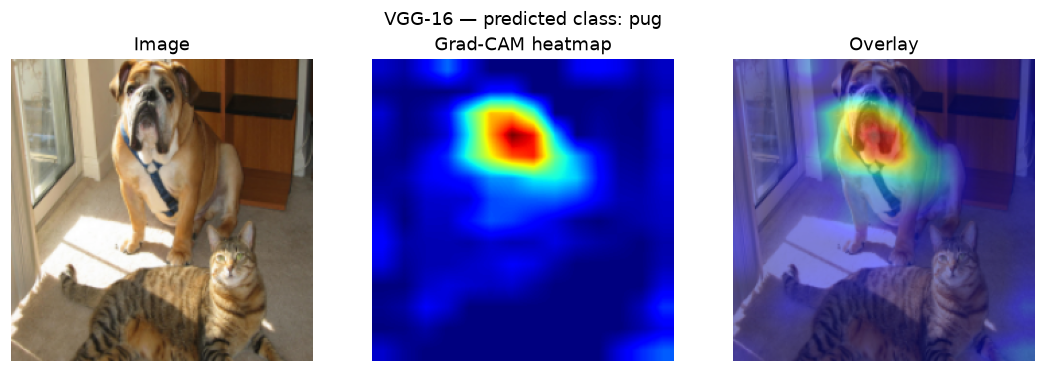

In [8]:
cam_vgg = GradCAM(vgg, vgg.features[29])
heat_pred, c = cam_vgg(x)
print("Explaining:", labels[c], f"(p = {probs_vgg[c]:.3f})")
show_cam(rgb, heat_pred, f"VGG-16 — predicted class: {labels[c]}")

### 5.1 Learning component — check against the `pytorch-grad-cam` library
To make sure the hand-written version is correct, run the same thing with the [`pytorch-grad-cam`](https://github.com/jacobgil/pytorch-grad-cam) library and compare. A correlation close to 1 means the two heatmaps are the same.

Correlation (ours vs library): 1.0000


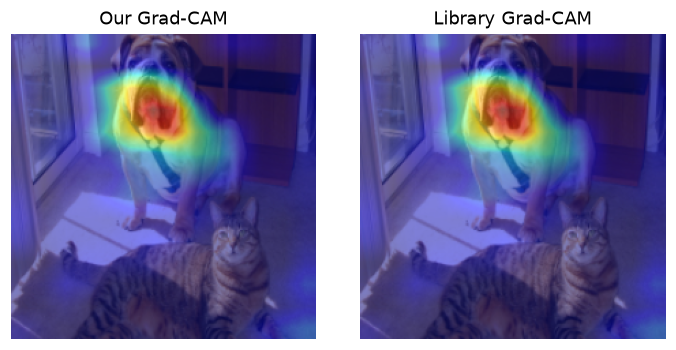

In [9]:
from pytorch_grad_cam import GradCAM as LibGradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

with LibGradCAM(model=vgg, target_layers=[vgg.features[29]]) as lib_cam:
    heat_lib = lib_cam(input_tensor=x.clone().requires_grad_(True), targets=[ClassifierOutputTarget(pred_vgg)])[0]

r = np.corrcoef(heat_pred.ravel(), heat_lib.ravel())[0, 1]
print(f"Correlation (ours vs library): {r:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(6.5, 3.2))
ax[0].imshow(overlay(rgb, heat_pred)); ax[0].set_title("Our Grad-CAM")
ax[1].imshow(overlay(rgb, heat_lib)); ax[1].set_title("Library Grad-CAM")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 6. Experiment 1 — a different target class
Same image, same model, same layer — only the class we ask about changes. We compare the predicted dog class with the highest-ranked **cat** class (ImageNet cats are classes 281–285).

To put a number on "where does the heatmap look", we split the image in two: the dog is in the **top half** and the cat is in the **bottom-right**. We report what share of the heatmap's total weight falls in each region.

Dog class: pug          p = 0.366
Cat class: tiger cat    p = 0.014


pug          heatmap -> dog region 69%, cat region 16%
tiger cat    heatmap -> dog region 13%, cat region 68%


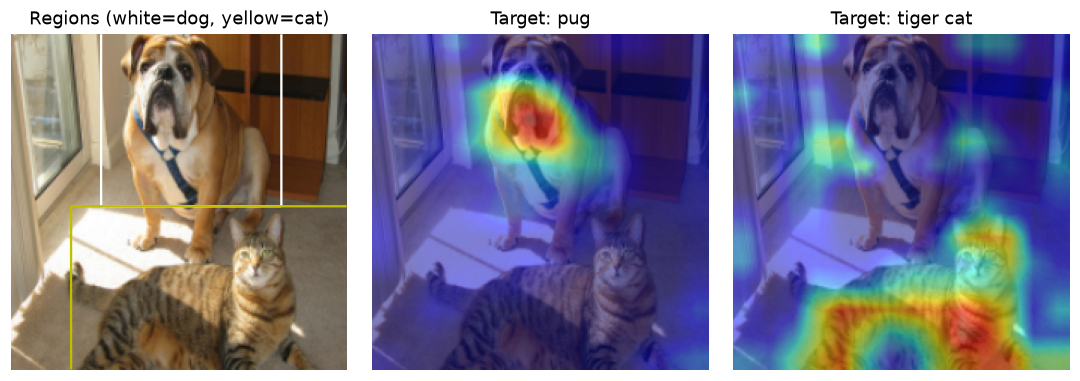

In [10]:
cat_classes = range(281, 286)                       # tabby, tiger cat, Persian, Siamese, Egyptian cat
cat_c = max(cat_classes, key=lambda i: probs_vgg[i].item())
print(f"Dog class: {labels[pred_vgg]:<12} p = {probs_vgg[pred_vgg]:.3f}")
print(f"Cat class: {labels[cat_c]:<12} p = {probs_vgg[cat_c]:.3f}")

heat_cat, _ = cam_vgg(x, cat_c)

# rough regions on the 224x224 crop (checked visually on the image above)
dog_box = np.zeros((224, 224), bool); dog_box[:115, 60:180] = True
cat_box = np.zeros((224, 224), bool); cat_box[115:, 40:] = True

def share(cam, box):
    return cam[box].sum() / cam.sum()

for name, h in [(labels[pred_vgg], heat_pred), (labels[cat_c], heat_cat)]:
    print(f"{name:<12} heatmap -> dog region {share(h, dog_box):.0%}, cat region {share(h, cat_box):.0%}")

fig, ax = plt.subplots(1, 3, figsize=(10, 3.4))
ax[0].imshow(rgb); ax[0].contour(dog_box, colors="w"); ax[0].contour(cat_box, colors="y"); ax[0].set_title("Regions (white=dog, yellow=cat)")
ax[1].imshow(overlay(rgb, heat_pred)); ax[1].set_title(f"Target: {labels[pred_vgg]}")
ax[2].imshow(overlay(rgb, heat_cat)); ax[2].set_title(f"Target: {labels[cat_c]}")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

### 6.1 Learning component — Grad-CAM for the top-5 classes
Looking at the top-5 classes shows whether similar classes (e.g. different dog breeds) share the same evidence.

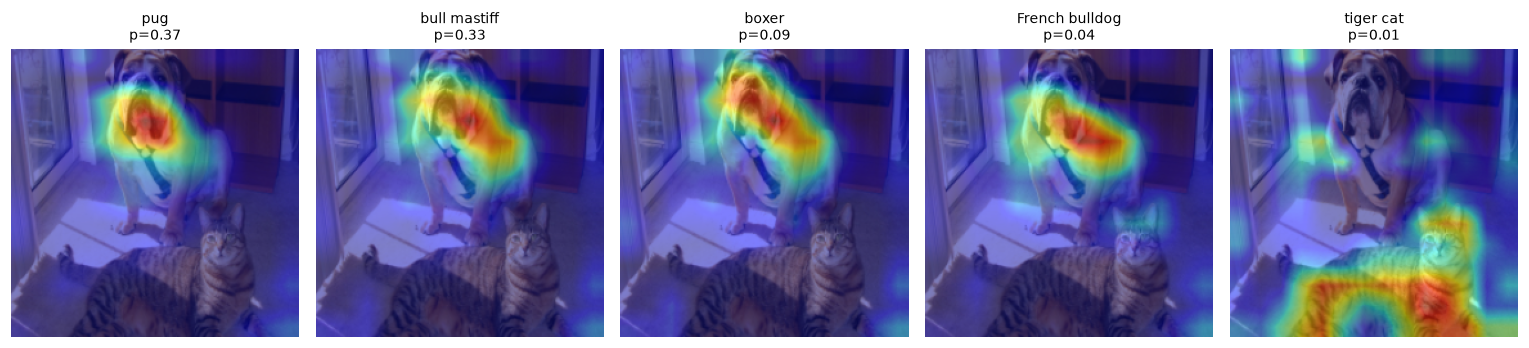

In [11]:
top5 = probs_vgg.topk(5).indices.tolist()
fig, ax = plt.subplots(1, 5, figsize=(14, 3.2))
for a, ci in zip(ax, top5):
    h, _ = cam_vgg(x, ci)
    a.imshow(overlay(rgb, h)); a.set_title(f"{labels[ci]}\np={probs_vgg[ci]:.2f}", fontsize=9); a.axis("off")
plt.tight_layout(); plt.show()

## 7. Learning component — changing the layer
The aim also mentions the layer. We run Grad-CAM on the last conv layer of blocks 3, 4 and 5 of VGG-16. Earlier layers have larger maps (finer detail) but their features are simpler (edges, textures), so they are less tied to the class.

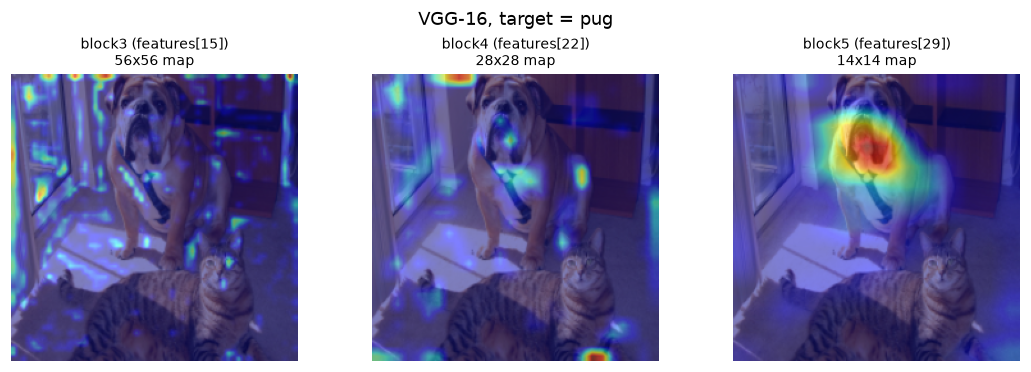

In [12]:
layers = {"block3 (features[15])": 15, "block4 (features[22])": 22, "block5 (features[29])": 29}
fig, ax = plt.subplots(1, 3, figsize=(10, 3.4))
for a, (name, i) in zip(ax, layers.items()):
    gc = GradCAM(vgg, vgg.features[i])
    h, _ = gc(x, pred_vgg)
    gc.remove()
    size = vgg.features[:i + 1](x).shape[-1]
    a.imshow(overlay(rgb, h)); a.set_title(f"{name}\n{size}x{size} map", fontsize=9); a.axis("off")
fig.suptitle(f"VGG-16, target = {labels[pred_vgg]}"); plt.tight_layout(); plt.show()

## 8. Experiment 2 — a different model (AlexNet)
AlexNet is older and shallower (5 conv layers vs 13 in VGG-16). We first check its prediction, then run Grad-CAM on its last conv block (`features[11]`, the ReLU after conv5, a 13×13 map) for the same two classes.

In [13]:
alex = models.alexnet(weights=models.AlexNet_Weights.IMAGENET1K_V1).to(device).eval().requires_grad_(False)
print(alex.features)
probs_alex = top_k(alex, x)

Sequential(
  (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
  (1): ReLU(inplace=True)
  (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (4): ReLU(inplace=True)
  (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (7): ReLU(inplace=True)
  (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (9): ReLU(inplace=True)
  (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (11): ReLU(inplace=True)
  (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
)
1. Rhodesian ridgeback    (class 159)  p = 0.200
2. malinois               (class 225)  p = 0.113
3. bull mastiff           (class 243)  p = 0.108
4. bloodhound             (class 163)  p = 0.081
5. redbone                (class 168) 

AlexNet, pug          -> dog region 53%, cat region 15%
AlexNet, tiger cat    -> dog region 26%, cat region 53%


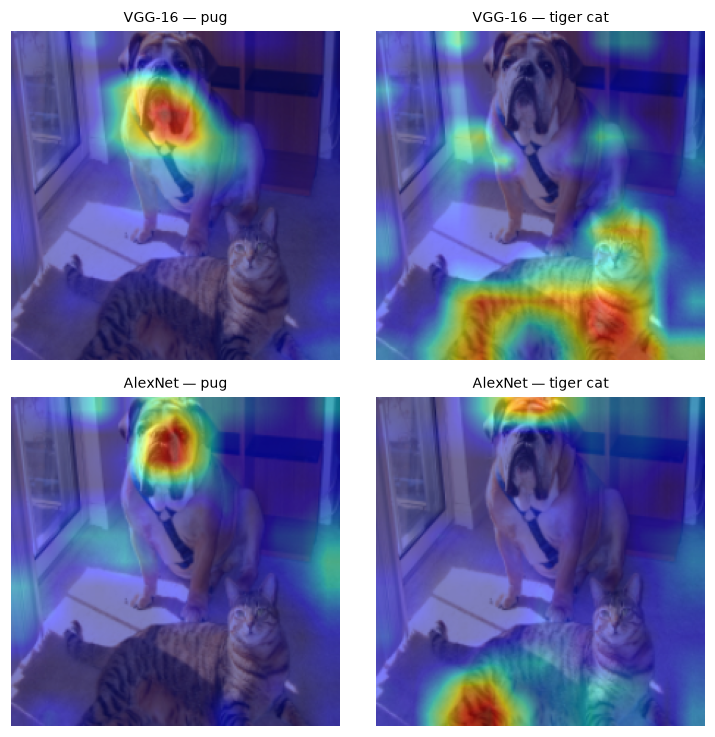

In [14]:
cam_alex = GradCAM(alex, alex.features[11])
heat_alex_dog, _ = cam_alex(x, pred_vgg)
heat_alex_cat, _ = cam_alex(x, cat_c)

for name, h in [(labels[pred_vgg], heat_alex_dog), (labels[cat_c], heat_alex_cat)]:
    print(f"AlexNet, {name:<12} -> dog region {share(h, dog_box):.0%}, cat region {share(h, cat_box):.0%}")

fig, ax = plt.subplots(2, 2, figsize=(6.8, 6.8))
for row, (model_name, hd, hc) in enumerate([("VGG-16", heat_pred, heat_cat), ("AlexNet", heat_alex_dog, heat_alex_cat)]):
    ax[row, 0].imshow(overlay(rgb, hd)); ax[row, 0].set_title(f"{model_name} — {labels[pred_vgg]}", fontsize=9)
    ax[row, 1].imshow(overlay(rgb, hc)); ax[row, 1].set_title(f"{model_name} — {labels[cat_c]}", fontsize=9)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

How similar are the two models' heatmaps? Correlation of 1 = identical, 0 = unrelated.

In [15]:
for name, a, b in [(labels[pred_vgg], heat_pred, heat_alex_dog), (labels[cat_c], heat_cat, heat_alex_cat)]:
    print(f"{name:<12} VGG vs AlexNet correlation: {np.corrcoef(a.ravel(), b.ravel())[0, 1]:.3f}")

pug          VGG vs AlexNet correlation: 0.382
tiger cat    VGG vs AlexNet correlation: 0.416


## 9. Learning component — Grad-CAM++
Grad-CAM gives every pixel of a feature map the **same** weight (the plain average gradient). Grad-CAM++ (Chattopadhay et al., 2018) uses a weighted average instead, so pixels with **positive** gradients count more. This usually makes the heatmap cover **more of the object** instead of only its strongest part.

Only the weight formula changes, so we reuse our `GradCAM` class and override `weights`:

α<sub>ij</sub> = g² / (2g² + ΣA · g³),  weight<sub>k</sub> = Σ<sub>ij</sub> α<sub>ij</sub> · ReLU(g)

Correlation (our Grad-CAM++ vs library): 1.0000

method      class      dog reg. cat reg.  coverage
Grad-CAM    pug             69%      16%        5%
Grad-CAM    tiger cat       13%      68%       14%
Grad-CAM++  pug             54%      32%        9%
Grad-CAM++  tiger cat       42%      43%       19%


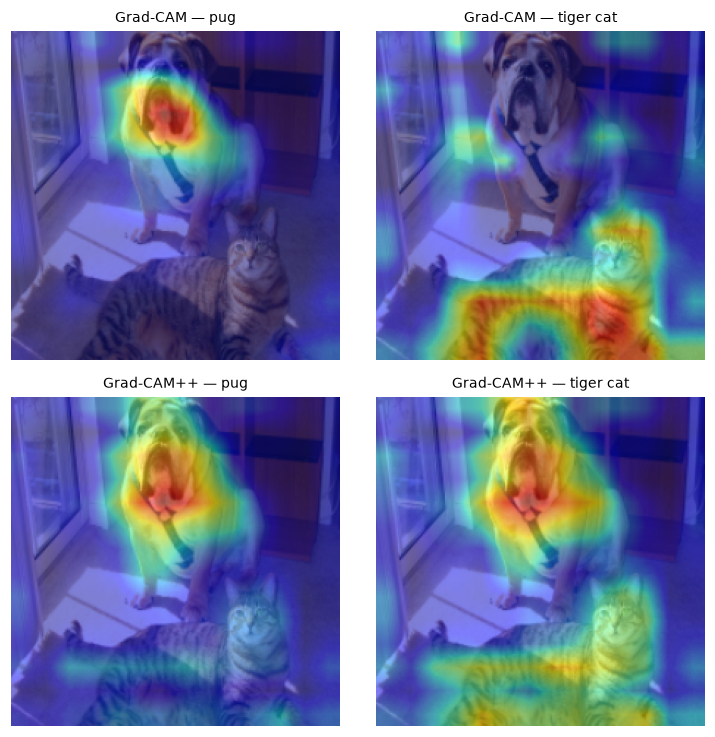

In [16]:
class GradCAMPlusPlus(GradCAM):
    def weights(self, A, G):
        g2, g3 = G ** 2, G ** 3
        sum_A = A.sum(dim=(1, 2), keepdim=True)
        a = g2 / (2 * g2 + sum_A * g3 + 1e-6)
        a = torch.where(G != 0, a, torch.zeros_like(a))           # no gradient -> no weight
        return (a * F.relu(G)).sum(dim=(1, 2))

campp_vgg = GradCAMPlusPlus(vgg, vgg.features[29])
heatpp_pred, _ = campp_vgg(x, pred_vgg)
heatpp_cat, _ = campp_vgg(x, cat_c)

# check against the library version
from pytorch_grad_cam import GradCAMPlusPlus as LibGradCAMPP
with LibGradCAMPP(model=vgg, target_layers=[vgg.features[29]]) as lib_pp:
    lib_heatpp = lib_pp(input_tensor=x.clone().requires_grad_(True), targets=[ClassifierOutputTarget(pred_vgg)])[0]
print(f"Correlation (our Grad-CAM++ vs library): {np.corrcoef(heatpp_pred.ravel(), lib_heatpp.ravel())[0, 1]:.4f}\n")

# coverage = share of pixels with heat > 0.5 (how much of the image is 'lit up')
print(f"{'method':<11} {'class':<10} {'dog reg.':>8} {'cat reg.':>8} {'coverage':>9}")
for method, hd, hc in [("Grad-CAM", heat_pred, heat_cat), ("Grad-CAM++", heatpp_pred, heatpp_cat)]:
    for cname, h in [(labels[pred_vgg], hd), (labels[cat_c], hc)]:
        print(f"{method:<11} {cname:<10} {share(h, dog_box):>8.0%} {share(h, cat_box):>8.0%} {(h > 0.5).mean():>9.0%}")

fig, ax = plt.subplots(2, 2, figsize=(6.8, 6.8))
for row, (method, hd, hc) in enumerate([("Grad-CAM", heat_pred, heat_cat), ("Grad-CAM++", heatpp_pred, heatpp_cat)]):
    ax[row, 0].imshow(overlay(rgb, hd)); ax[row, 0].set_title(f"{method} — {labels[pred_vgg]}", fontsize=9)
    ax[row, 1].imshow(overlay(rgb, hc)); ax[row, 1].set_title(f"{method} — {labels[cat_c]}", fontsize=9)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

## 10. Learning component — Guided Grad-CAM
Grad-CAM is coarse (14×14). **Guided Backpropagation** gives pixel-level detail: it back-propagates the class score to the input pixels but, at every ReLU, lets only **positive** gradients through. On its own it is *not* class-specific — it looks almost the same for every class. **Guided Grad-CAM** multiplies the two: sharp detail from Guided Backprop, class focus from Grad-CAM.

To do this we copy VGG-16 and swap every ReLU for a "guided" ReLU with a custom backward pass.

Dog-vs-cat similarity, Guided Backprop : 0.998  (high = not class-specific)
Dog-vs-cat similarity, Guided Grad-CAM : -0.043


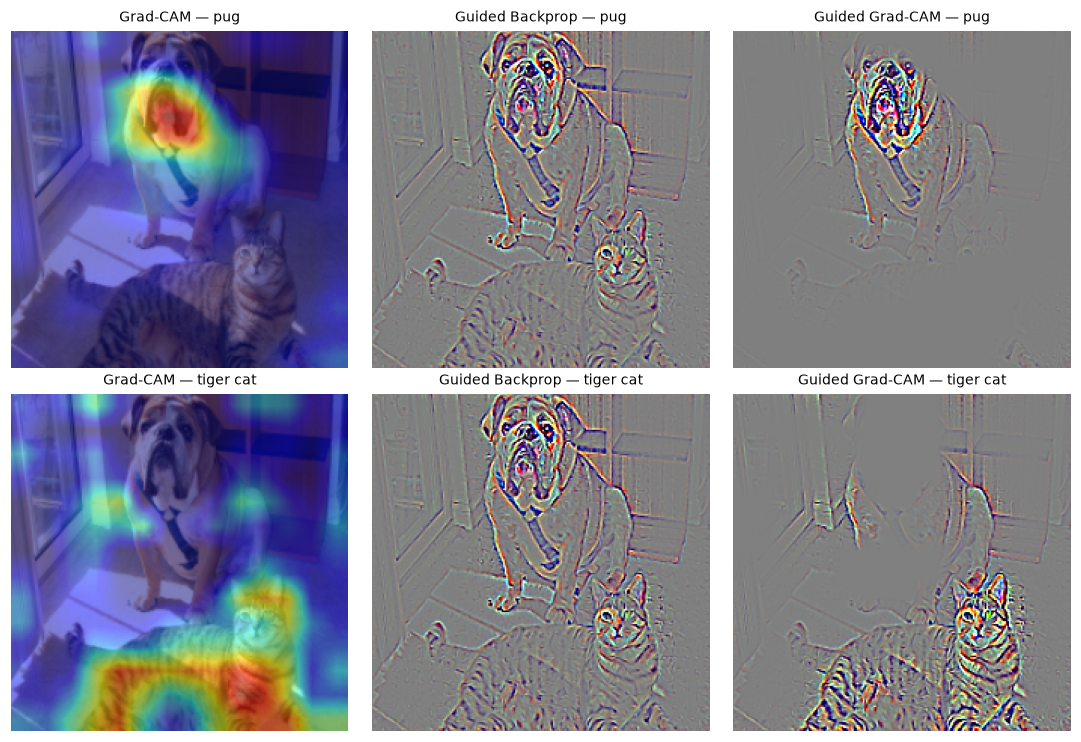

In [17]:
class GuidedReLU(torch.autograd.Function):
    @staticmethod
    def forward(ctx, inp):
        out = inp.clamp(min=0)
        ctx.save_for_backward(out)
        return out

    @staticmethod
    def backward(ctx, grad_out):
        out, = ctx.saved_tensors
        return grad_out.clamp(min=0) * (out > 0)       # positive gradient AND positive activation

class GuidedReLUModule(torch.nn.Module):
    def forward(self, x):
        return GuidedReLU.apply(x)

gb_model = models.vgg16(weights=weights_vgg).to(device).eval().requires_grad_(False)
for seq in (gb_model.features, gb_model.classifier):
    for i, m in enumerate(seq):
        if isinstance(m, torch.nn.ReLU):
            seq[i] = GuidedReLUModule()

def guided_backprop(model, x, c):
    x = x.clone().requires_grad_(True)
    model.zero_grad()
    model(x)[0, c].backward()
    return x.grad[0].permute(1, 2, 0).cpu().numpy()        # (224, 224, 3)

def to_img(g):                                             # centre on grey so +/- gradients are visible
    return ((g - g.mean()) / (g.std() + 1e-8) * 0.15 + 0.5).clip(0, 1)

gb_dog, gb_cat = guided_backprop(gb_model, x, pred_vgg), guided_backprop(gb_model, x, cat_c)
ggc_dog, ggc_cat = gb_dog * heat_pred[..., None], gb_cat * heat_cat[..., None]

corr = lambda a, b: np.corrcoef(np.abs(a).sum(-1).ravel(), np.abs(b).sum(-1).ravel())[0, 1]
print(f"Dog-vs-cat similarity, Guided Backprop : {corr(gb_dog, gb_cat):.3f}  (high = not class-specific)")
print(f"Dog-vs-cat similarity, Guided Grad-CAM : {corr(ggc_dog, ggc_cat):.3f}")

fig, ax = plt.subplots(2, 3, figsize=(10, 6.8))
for row, (cname, h, gb, ggc) in enumerate([(labels[pred_vgg], heat_pred, gb_dog, ggc_dog),
                                           (labels[cat_c], heat_cat, gb_cat, ggc_cat)]):
    ax[row, 0].imshow(overlay(rgb, h)); ax[row, 0].set_title(f"Grad-CAM — {cname}", fontsize=9)
    ax[row, 1].imshow(to_img(gb)); ax[row, 1].set_title(f"Guided Backprop — {cname}", fontsize=9)
    ax[row, 2].imshow(to_img(ggc)); ax[row, 2].set_title(f"Guided Grad-CAM — {cname}", fontsize=9)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

del gb_model, seq, m; torch.cuda.empty_cache()

## 11. Learning component — measuring faithfulness (deletion & insertion)
A heatmap can *look* right and still not reflect what the model uses. Deletion and insertion (Petsiuk et al., 2018) **test** it:
- **Deletion:** blur the image pixels in order of importance (most important first) and watch the class probability. A good heatmap makes it **drop fast** → **low** area under the curve (AUC).
- **Insertion:** start from a fully blurred image and put back the sharp pixels in order of importance. A good heatmap makes it **rise fast** → **high** AUC.

We blur instead of painting pixels black, because a black hole is an unnatural shape the model may react to on its own. A **random** heatmap is the baseline every method must beat.

class      method       deletion AUC (low=good)  insertion AUC (high=good)


pug        Grad-CAM                      0.0087                     0.6037


pug        Grad-CAM++                    0.0136                     0.4281


pug        Random                        0.0407                     0.0262


tiger cat  Grad-CAM                      0.0004                     0.1167


tiger cat  Grad-CAM++                    0.0121                     0.0108


tiger cat  Random                        0.0025                     0.0014


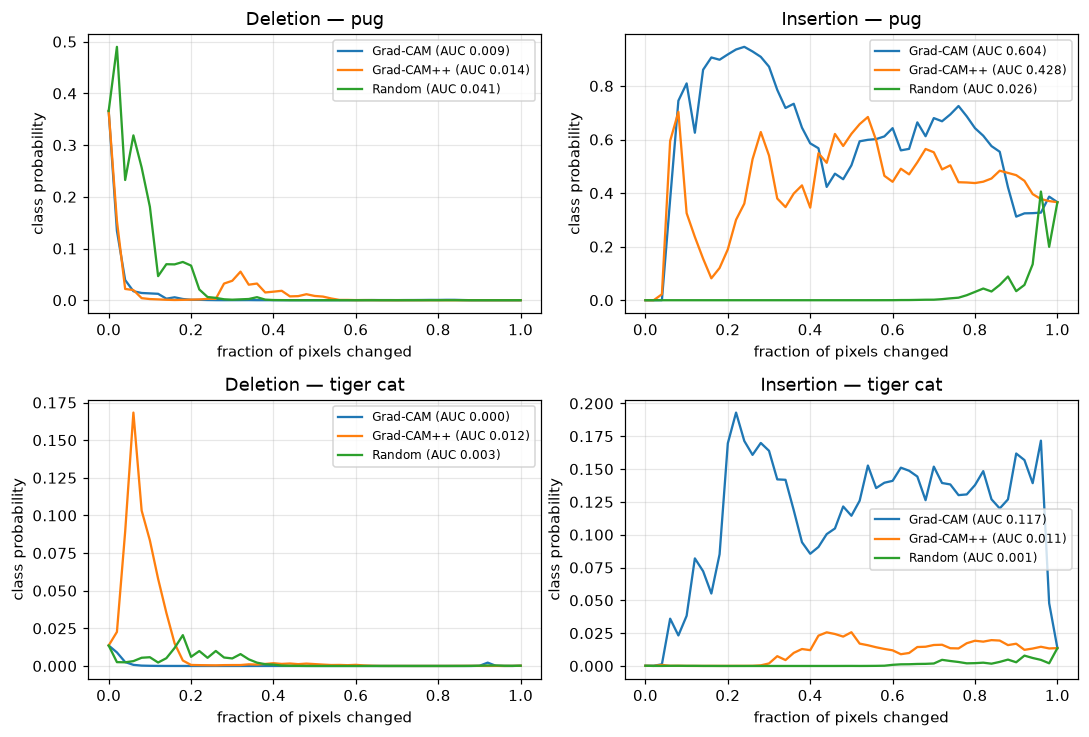

In [18]:
from torchvision.transforms.functional import gaussian_blur

blurred = gaussian_blur(x, kernel_size=51, sigma=20.0)
rng = np.random.default_rng(0)

def deletion_insertion(model, heat, c, steps=50, batch=8):    # small batches fit a 4 GB GPU
    heat = heat + 1e-6 * rng.random(heat.shape)                       # break ties among zero pixels randomly
    order = torch.from_numpy(heat.ravel()).argsort(descending=True).to(device)
    n = order.numel()
    masks = torch.zeros(steps + 1, n, device=device)
    for s, k in enumerate(torch.linspace(0, n, steps + 1).long()):
        masks[s, order[:k]] = 1                                       # 1 = pixel already deleted/inserted
    masks = masks.view(-1, 1, 224, 224)
    curves = []
    for imgs in (x * (1 - masks) + blurred * masks,                   # deletion
                 blurred * (1 - masks) + x * masks):                  # insertion
        with torch.no_grad():
            p = torch.cat([F.softmax(model(b), 1)[:, c] for b in imgs.split(batch)])
        curves.append(p.cpu().numpy())
    frac = np.linspace(0, 1, steps + 1)
    return frac, curves[0], curves[1], np.trapezoid(curves[0], frac), np.trapezoid(curves[1], frac)

methods = {"Grad-CAM": (heat_pred, heat_cat), "Grad-CAM++": (heatpp_pred, heatpp_cat),
           "Random": (rng.random((224, 224)), rng.random((224, 224)))}

fig, ax = plt.subplots(2, 2, figsize=(10, 6.8))
print(f"{'class':<10} {'method':<11} {'deletion AUC (low=good)':>24} {'insertion AUC (high=good)':>26}")
for row, (cname, c) in enumerate([(labels[pred_vgg], pred_vgg), (labels[cat_c], cat_c)]):
    for name, heats in methods.items():
        frac, pd_, pi_, auc_d, auc_i = deletion_insertion(vgg, heats[row], c)
        print(f"{cname:<10} {name:<11} {auc_d:>24.4f} {auc_i:>26.4f}")
        ax[row, 0].plot(frac, pd_, label=f"{name} (AUC {auc_d:.3f})")
        ax[row, 1].plot(frac, pi_, label=f"{name} (AUC {auc_i:.3f})")
    ax[row, 0].set_title(f"Deletion — {cname}"); ax[row, 1].set_title(f"Insertion — {cname}")
for a in ax.ravel():
    a.set_xlabel("fraction of pixels changed"); a.set_ylabel("class probability"); a.legend(fontsize=8); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 12. Learning component — sanity check (model randomisation)
Adebayo et al. (2018) showed that some explanation methods give almost the same picture even when the model's weights are **random** — so they are really just edge detectors, not explanations. The test: randomise the layers one by one from the top (classifier first, then conv5_3, conv5_2, …) and compare the new heatmap with the original. A trustworthy method's heatmap should **change a lot** (low rank correlation).

We randomise a fresh copy of VGG-16 so the original model is untouched.

original      rank correlation with original:  1.000
+ classifier  rank correlation with original:  0.571
+ conv5_3     rank correlation with original:  0.011
+ conv5_2     rank correlation with original:  0.138
+ conv5_1     rank correlation with original:  0.110


+ conv4_3     rank correlation with original:  0.153


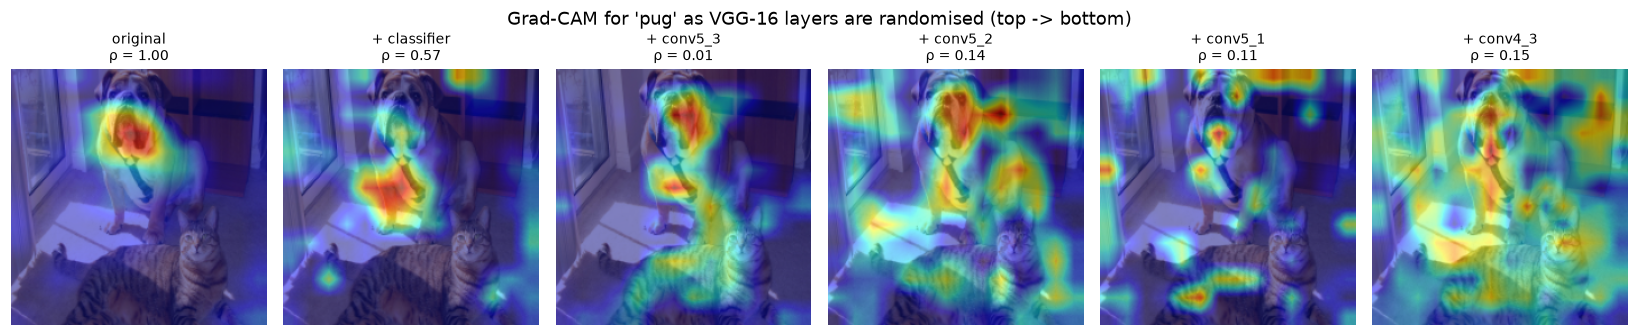

In [19]:
from scipy.stats import spearmanr

torch.manual_seed(0)
rand_vgg = models.vgg16(weights=weights_vgg).to(device).eval().requires_grad_(False)
cam_rand = GradCAM(rand_vgg, rand_vgg.features[29])
stages = [("original", None), ("+ classifier", rand_vgg.classifier), ("+ conv5_3", rand_vgg.features[28]),
          ("+ conv5_2", rand_vgg.features[26]), ("+ conv5_1", rand_vgg.features[24]), ("+ conv4_3", rand_vgg.features[21])]

fig, ax = plt.subplots(1, len(stages), figsize=(15, 3.2))
for a, (name, block) in zip(ax, stages):
    if block is not None:                                  # cascading: earlier randomisations are kept
        for m in block.modules():
            if hasattr(m, "reset_parameters"):
                m.reset_parameters()
    h, _ = cam_rand(x, pred_vgg)
    rho = spearmanr(heat_pred.ravel(), h.ravel()).statistic
    print(f"{name:<13} rank correlation with original: {rho:6.3f}")
    a.imshow(overlay(rgb, h)); a.set_title(f"{name}\nρ = {rho:.2f}", fontsize=9); a.axis("off")
fig.suptitle("Grad-CAM for 'pug' as VGG-16 layers are randomised (top -> bottom)")
plt.tight_layout(); plt.show()

cam_rand.remove(); del rand_vgg; torch.cuda.empty_cache()

## 13. Observations
| Experiment | What changed | What we saw |
|---|---|---|
| Predicted class | – | VGG-16 says **pug** (0.37), then bull mastiff (0.33). ImageNet has no "English bulldog" class, so a flat-faced breed is a sensible near-miss. The heatmap sits on the dog's **face and chest**. |
| **Exp 1: different class** | pug → tiger cat | The heatmap **jumps from the dog to the cat**. Pug map: 69% of its weight on the dog region; tiger-cat map: 68% on the cat region. Grad-CAM is **class-discriminative** even when the class has only 1.4% probability. |
| **Exp 2: different model** | VGG-16 → AlexNet | AlexNet predicts **Rhodesian ridgeback** (0.20) — a less fitting breed. Its maps are blurrier and less focused: for "tiger cat" it puts 26% on the dog's head. Correlation with the VGG maps is only ~0.4. |

**Learning component results**

| Section | What we saw |
|---|---|
| Library check (5.1, 9) | Our Grad-CAM **and** Grad-CAM++ both match `pytorch-grad-cam` exactly (r = 1.0000). |
| Top-5 classes (6.1) | All four dog breeds light up the same face/chest area; only the cat class moves. |
| Layers (7) | block3/block4 maps are scattered noise; only the last block gives an object-level map. |
| Grad-CAM++ (9) | Covers more area (pug 5% → 9% of pixels lit) but is **less class-specific** here: its tiger-cat map is split 42% dog / 43% cat. |
| Guided Grad-CAM (10) | Guided Backprop alone is almost identical for dog and cat (similarity 0.998) — it is *not* class-specific. Multiplying by Grad-CAM fixes this (similarity −0.04) and gives sharp, pixel-level detail (eyes, nose, stripes). |
| Deletion / insertion (11) | Grad-CAM beats the random baseline on every score (pug deletion AUC 0.009 vs 0.041; insertion 0.60 vs 0.03). Grad-CAM++ is worse than Grad-CAM on all four scores. Inserting only the dog pixels pushes "pug" to ~0.95 — higher than the 0.37 on the full image, because the cat is no longer competing. |
| Sanity check (12) | Randomising the classifier drops the rank correlation to 0.57; randomising conv5_3 drops it to **0.01**. Grad-CAM really depends on the learned weights — it **passes** the sanity check. |

**Take-aways**
1. Grad-CAM depends on **the class we ask about** — the same image gives different maps for different classes.
2. It depends on **the layer** — deep layers give meaningful maps, shallow layers give noise.
3. It depends on **the model** — a heatmap explains *one model's* decision, not "the truth" about the image.
4. A heatmap that *looks* good should still be **tested**: deletion/insertion showed plain Grad-CAM is more faithful than Grad-CAM++ for this image, and the randomisation test showed Grad-CAM is a real explanation, not just an edge detector.